# Forecasting with ARMA Models

<a href="https://colab.research.google.com/github/febse/ts2025/blob/main/05-ARMA-Fitting-Class.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open Class Version In Colab"/>Class Version</a>


In [72]:
# A purely random process with a standard deviation of 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import arma_generate_sample
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

np.random.seed(12)  # for reproducibility

# Model parameters
phi_1 = 0.8  # AR1 coefficient
phi_2 = 0 # set to -0.6 for AR(2) process with complex roots
theta_1 = 0  # MA coefficient (set to something non-zero for ARMA process. For a pure MA process, set phi_1=0 and phi_2=0 and theta_1 to somethig non-zero)
theta_2 = 0

sigma = 1  # standard deviation of the purely random process
n = 100

# True model as fixed (not estimated) ARIMA parameters: [const, phi_1, sigma2]
# (valid for the AR(1) case; add phi_2, theta_1, theta_2 entries in statsmodels order if you change them)
true_params = [0.0, phi_1, (1.5 * sigma) ** 2]

noise = arma_generate_sample(ar=[1], ma=[1], nsample=n, scale=sigma)

dt = arma_generate_sample(ar=[1, -phi_1, -phi_2], ma=[1, -theta_1, -theta_2], nsample=n, scale= 1.5 * sigma)

# Hold out the final 20 observations as test data.
# Everything below (plots, model fitting, diagnostics) uses the training data only.
forecast_steps = 20
test_start = len(dt) - forecast_steps
dt_train = dt[:test_start]
dt_test = dt[test_start:]

# Check the first 10 values of the training series
dt_train[:10]

array([-2.04845972, -3.43043435, -2.72044567, -2.29642173, -2.21334145,
       -2.6183875 , -3.74871791, -4.17239799,  1.22461092,  0.0405669 ])

## Fitting AR(p) Models

$$
x_t = \phi_0 + \phi_1 x_{t-1} + \phi_2 x_{t-2} + ... + \phi_p x_{t-p} + e_t
$$

where $e_t \sim N(0, \sigma_e^2), E(e_t e_{t-k}) = 0 \text{ for } k \neq 0$.

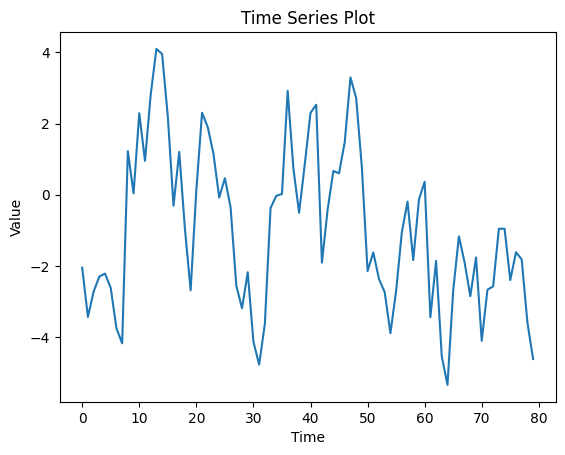

In [73]:
# Plot the series

plt.plot(dt_train)
plt.title('Time Series Plot')
plt.xlabel('Time')
plt.ylabel('Value')
plt.show()


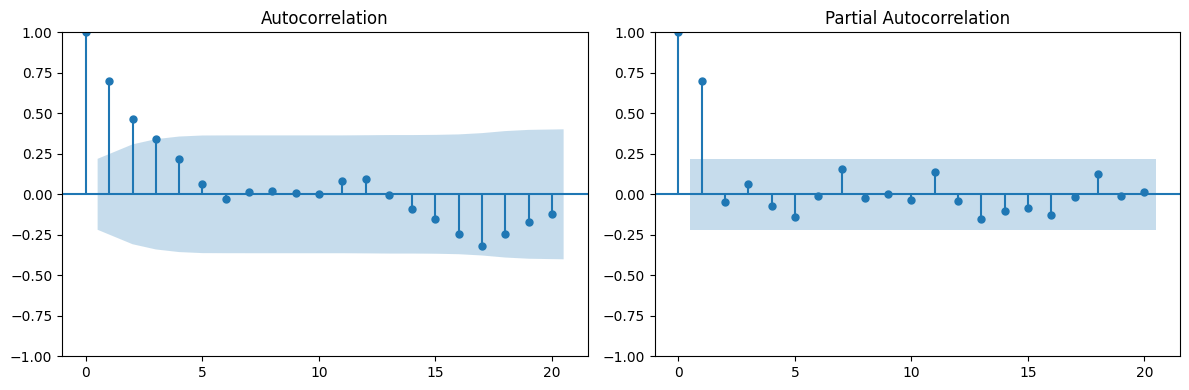

In [74]:
# Plot ACF and PACF

fix, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(dt_train, ax=ax[0], lags=20)
plot_pacf(dt_train, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [75]:
# Use statsmodels to fit an AR(1) model to the training data and print the summary

from statsmodels.tsa.arima.model import ARIMA

model_ar1 = ARIMA(dt_train, order=(1, 0, 0))
model_ar1_fit = model_ar1.fit()

print(model_ar1_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   80
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -150.534
Date:                 ср, 18 ное 2026   AIC                            307.068
Time:                        15:42:04   BIC                            314.214
Sample:                             0   HQIC                           309.933
                                 - 80                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1004      0.634     -1.736      0.083      -2.343       0.142
ar.L1          0.7166      0.083      8.627      0.000       0.554       0.879
sigma2         2.5004      0.442      5.658      0.0

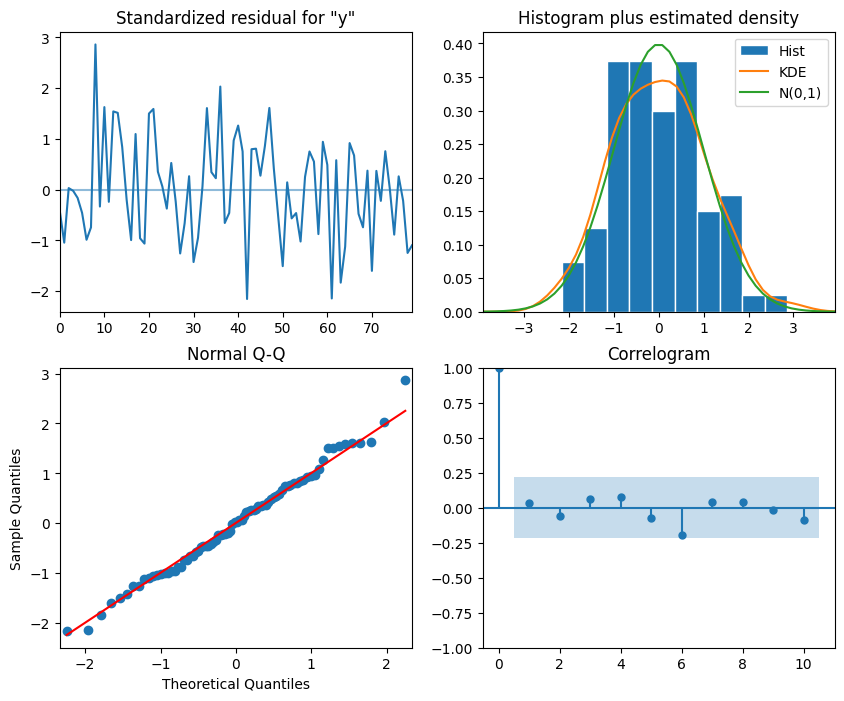

In [76]:
model_ar1_fit.plot_diagnostics(figsize=(10, 8))
plt.show()

## The Ljung-Box Test

Assumptions: the residuals $\hat e_t$ come from a model with $p + q$ estimated ARMA coefficients.

$$
Q=T(T+2)\sum _{k=1}^{h}{\frac {{\hat {\rho }}_{k}^{2}}{T-k}} \;\underset{H_0}{\approx}\; \chi^2(h - p - q)
$$

$$
\begin{align*}
H^{h}_0: & \rho_1 = \rho_2 = \ldots = \rho_{h} = 0 \\
H^{h}_1: & \text{ at least one of } \rho_k \neq 0, \quad k = 1,\ldots, h
\end{align*}
$$

The approximation is valid for large $T$ and requires $h > p + q$. The degrees of freedom are reduced by the number of estimated ARMA coefficients ($p + q$; the constant and $\sigma^2$ are not counted). For a model with **fixed** (not estimated) coefficients no adjustment is needed: the df is $h$.

Note: `test_serial_correlation("ljungbox")` in statsmodels does **not** adjust the df by default (`df_adjust=False`), and with `df_adjust=True` it also counts the constant, so we call `acorr_ljungbox` with `model_df = p + q` ourselves.

In [77]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Estimated AR(1): df = h - (p + q) = h - 1, so start at lag 2
estimated_lb = acorr_ljungbox(model_ar1_fit.resid, lags=range(2, 11), model_df=1)

print("Estimated AR(1) model (df = lag - 1)")
for lag, row in estimated_lb.iterrows():
    print(f"Lag {lag}, test statistic = {row['lb_stat']:.3f} with p-value {row['lb_pvalue']:.3f}")

# True model with fixed coefficients (nothing estimated): df = h
true_model_train = ARIMA(dt_train, order=(1, 0, 0)).smooth(true_params)
true_lb = acorr_ljungbox(true_model_train.resid, lags=range(1, 11), model_df=0)

print("\nTrue model, fixed coefficients (df = lag)")
for lag, row in true_lb.iterrows():
    print(f"Lag {lag}, test statistic = {row['lb_stat']:.3f} with p-value {row['lb_pvalue']:.3f}")

Estimated AR(1) model (df = lag - 1)
Lag 2, test statistic = 0.392 with p-value 0.531
Lag 3, test statistic = 0.732 with p-value 0.693
Lag 4, test statistic = 1.284 with p-value 0.733
Lag 5, test statistic = 1.720 with p-value 0.787
Lag 6, test statistic = 5.084 with p-value 0.406
Lag 7, test statistic = 5.233 with p-value 0.514
Lag 8, test statistic = 5.362 with p-value 0.616
Lag 9, test statistic = 5.391 with p-value 0.715
Lag 10, test statistic = 6.167 with p-value 0.723

True model, fixed coefficients (df = lag)
Lag 1, test statistic = 0.045 with p-value 0.833
Lag 2, test statistic = 1.052 with p-value 0.591
Lag 3, test statistic = 1.151 with p-value 0.765
Lag 4, test statistic = 1.514 with p-value 0.824
Lag 5, test statistic = 2.075 with p-value 0.839
Lag 6, test statistic = 5.742 with p-value 0.453
Lag 7, test statistic = 5.927 with p-value 0.548
Lag 8, test statistic = 5.953 with p-value 0.653
Lag 9, test statistic = 5.994 with p-value 0.740
Lag 10, test statistic = 7.151 with p

In [78]:
forecast = model_ar1_fit.get_forecast(steps=2)

print("Forecasts")
print(forecast.predicted_mean)

print("Standard errors")
print(forecast.se_mean)

Forecasts
[-3.61703254 -2.90383095]
Standard errors
[1.58127054 1.94536369]


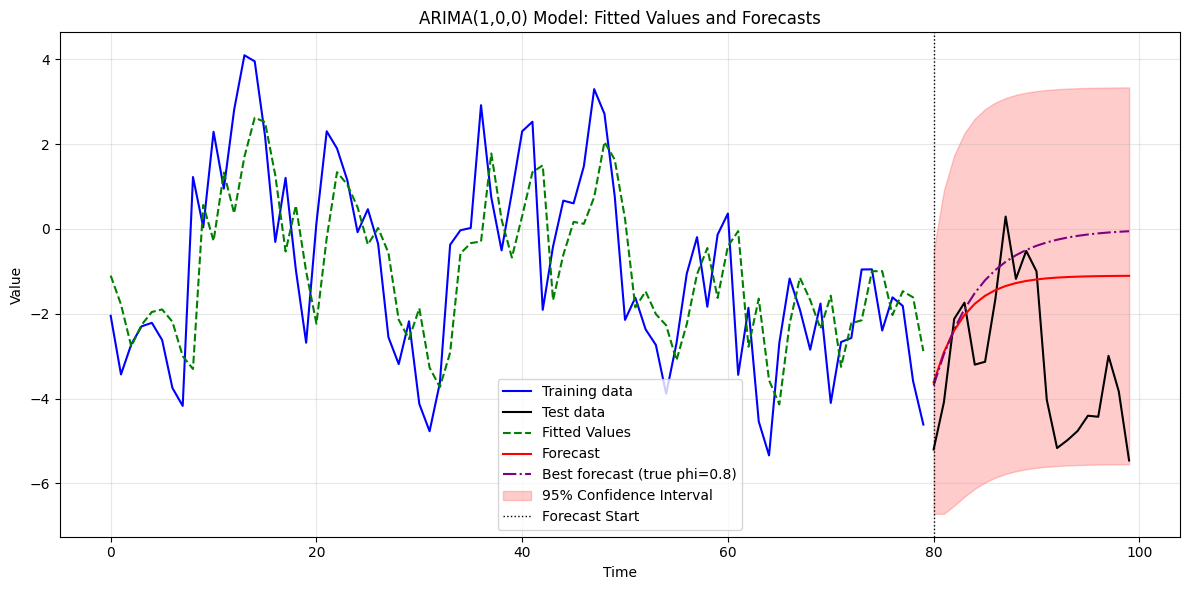

In [79]:
# Plot the prediction of the model

# Fitted AR(1) model (estimated on the training data in the cell above)
fitted_values = model_ar1_fit.fittedvalues
forecast = model_ar1_fit.forecast(steps=forecast_steps)
forecast_index = np.arange(test_start, len(dt))
actual_values = np.asarray(dt_test)

# Best predictions from the true model: an ARIMA(1,0,0) with fixed (not estimated)
# coefficients (true_model_train, created with .smooth() in the Ljung-Box cell)
best_forecast = np.asarray(true_model_train.forecast(steps=forecast_steps))

best_residuals = actual_values - best_forecast
best_mse = np.mean(best_residuals ** 2)

# Get forecast confidence intervals
forecast_result = model_ar1_fit.get_forecast(steps=forecast_steps)
forecast_ci = np.array(forecast_result.conf_int())  # Convert to numpy array

# Plot
plt.figure(figsize=(12, 6))
plt.plot(dt_train, label='Training data', color='blue', linewidth=1.5)
plt.plot(forecast_index, actual_values, label='Test data', color='black', linewidth=1.5)
plt.plot(fitted_values, label='Fitted Values', color='green', linewidth=1.5, linestyle='--')
plt.plot(forecast_index, forecast, label='Forecast', color='red', linewidth=1.5)
plt.plot(forecast_index, best_forecast, label='Best forecast (true phi=0.8)', color='purple', linewidth=1.5, linestyle='-.')
plt.fill_between(forecast_index, 
                 forecast_ci[:, 0],
                 forecast_ci[:, 1], 
                 color='red', alpha=0.2, label='95% Confidence Interval')
plt.axvline(x=test_start, color='black', linestyle=':', linewidth=1, label='Forecast Start')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('ARIMA(1,0,0) Model: Fitted Values and Forecasts')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [80]:
# MSE and residuals for forecasts over the complete test interval
fitted_model_forecast = np.asarray(model_ar1_fit.forecast(steps=forecast_steps))
fitted_residuals = np.asarray(dt_test) - fitted_model_forecast

ar0_model = ARIMA(dt_train, order=(0, 0, 0)).fit()
ar0_forecast = np.asarray(ar0_model.forecast(steps=forecast_steps))
ar0_residuals = np.asarray(dt_test) - ar0_forecast

ar1_model = model_ar1_fit
ar1_forecast = np.asarray(ar1_model.forecast(steps=forecast_steps))
ar1_residuals = np.asarray(dt_test) - ar1_forecast
true_residuals = np.asarray(dt_test) - best_forecast

true_model_mse = np.mean(true_residuals ** 2)
fitted_model_mse = np.mean(fitted_residuals ** 2)
ar0_mse = np.mean(ar0_residuals ** 2)
ar1_mse = np.mean(ar1_residuals ** 2)

print("Actual test data:")
print(np.asarray(dt_test))
print("\nFitted-model forecasts:")
print(fitted_model_forecast)
print("\nFitted-model residuals (actual - forecast):")
print(fitted_residuals)



Actual test data:
[-5.19984017 -4.08483949 -2.11972639 -1.73855343 -3.19931114 -3.13176618
 -1.65514749  0.29188713 -1.17702838 -0.51621202 -0.99845034 -4.02994693
 -5.16598317 -4.98211758 -4.76225788 -4.40362376 -4.42844188 -2.99166417
 -3.83184905 -5.45842433]

Fitted-model forecasts:
[-3.61703254 -2.90383095 -2.39274659 -2.0265006  -1.76404662 -1.57597059
 -1.44119423 -1.34461271 -1.27540185 -1.22580494 -1.19026351 -1.16479432
 -1.14654295 -1.13346392 -1.12409141 -1.11737501 -1.112562   -1.10911297
 -1.10664138 -1.10487022]

Fitted-model residuals (actual - forecast):
[-1.58280762 -1.18100855  0.27302019  0.28794717 -1.43526452 -1.55579559
 -0.21395326  1.63649984  0.09837346  0.70959292  0.19181317 -2.86515261
 -4.01944022 -3.84865366 -3.63816647 -3.28624875 -3.31587988 -1.88255119
 -2.72520768 -4.35355411]


In [81]:
print("\nMean squared error over the complete 20-observation test interval")
print(f"True model (phi_1 = {phi_1:.1f}): {true_model_mse:.6f}")
print(f"Fitted model: {fitted_model_mse:.6f}")
print(f"AR(0): {ar0_mse:.6f}")
print(f"AR(1): {ar1_mse:.6f}")


Mean squared error over the complete 20-observation test interval
True model (phi_1 = 0.8): 9.160780
Fitted model: 5.797198
AR(0): 7.800288
AR(1): 5.797198


## Information Criteria

### Akaike Information Criterion (AIC)

$$
AIC = -2 \underbrace{\log(L)}_{\text{Goodness of fit}} + 2 \underbrace{(p + q + k + 1)}_{\text{number of parameters}}
$$


$$
AICc = AIC + \frac{2(p + q + k + 1)(p + q + k + 2)}{T - p - q - k - 2}
$$

$$
BIC = AIC + (\log(T) - 2)(p + q + k + 1)
$$



## Simulation: Average Forecast MSE

A single train/test split is one random draw, and the 20 test observations are strongly autocorrelated. To compare the models fairly, we repeat the experiment many times: simulate a new AR(1) series, fit on the first 80 observations, and compute the MSE over the last 20.

- True model: AR(1) with fixed, known coefficients (nothing estimated).
- AR(1) estimated: correctly specified, but the constant, $\phi_1$ and $\sigma^2$ are estimated.
- AR(5) estimated: over-parameterized (the true $\phi_2 = \ldots = \phi_5 = 0$), so it pays a price for estimation noise.

What we expect to see is that on average, True $\le$ AR(1) $\le$ AR(5), but not in every single replication.

In [82]:
n_simulations = 500
rng = np.random.default_rng(2025)  # separate generator, keeps the simulation reproducible

horizon = np.arange(1, forecast_steps + 1)
mse_results = {"True model": [], "AR(1) estimated": [], "AR(5) estimated": []}

for _ in range(n_simulations):
    sim_series = arma_generate_sample(
        ar=[1, -phi_1, -phi_2], ma=[1, -theta_1, -theta_2],
        nsample=n, scale=1.5 * sigma, distrvs=rng.standard_normal,
    )
    sim_train, sim_test = sim_series[:test_start], sim_series[test_start:]

    # True model: fixed coefficients, no estimation
    true_forecast = ARIMA(sim_train, order=(1, 0, 0)).smooth(true_params).forecast(steps=forecast_steps)
    ar1_forecast_sim = ARIMA(sim_train, order=(1, 0, 0)).fit().forecast(steps=forecast_steps)
    ar5_forecast_sim = ARIMA(sim_train, order=(5, 0, 0)).fit().forecast(steps=forecast_steps)

    for name, fc in [("True model", true_forecast), ("AR(1) estimated", ar1_forecast_sim), ("AR(5) estimated", ar5_forecast_sim)]:
        mse_results[name].append(np.mean((sim_test - np.asarray(fc)) ** 2))

mse_table = pd.DataFrame(mse_results)

print(f"Average test MSE over {n_simulations} simulations")
print(mse_table.mean().round(3).to_string())
print("\nShare of simulations in which each model has the lowest MSE")
print((mse_table.idxmin(axis=1).value_counts() / n_simulations).round(3).to_string())

Average test MSE over 500 simulations
True model         5.445
AR(1) estimated    5.850
AR(5) estimated    5.975

Share of simulations in which each model has the lowest MSE
True model         0.504
AR(5) estimated    0.272
AR(1) estimated    0.224


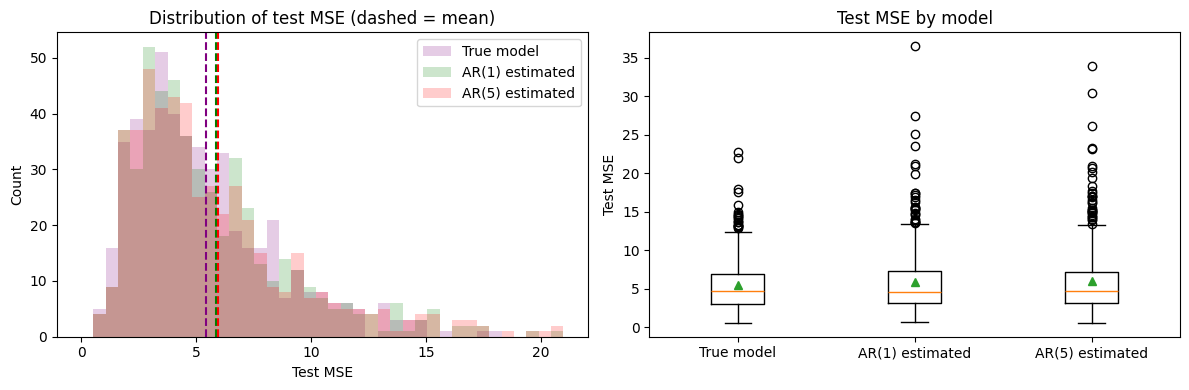

In [84]:
# Distribution of the MSE for each model
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

upper = mse_table.quantile(0.99).max()
bins = np.linspace(0, upper, 40)
for name, color in zip(mse_table.columns, ["purple", "green", "red"]):
    ax[0].hist(mse_table[name], bins=bins, alpha=0.2, color=color, label=name)
    ax[0].axvline(mse_table[name].mean(), color=color, linestyle="--")
ax[0].set_xlabel("Test MSE")
ax[0].set_ylabel("Count")
ax[0].set_title("Distribution of test MSE (dashed = mean)")
ax[0].legend()

ax[1].boxplot([mse_table[c] for c in mse_table.columns], tick_labels=mse_table.columns, showmeans=True)
ax[1].set_ylabel("Test MSE")
ax[1].set_title("Test MSE by model")

plt.tight_layout()
plt.show()